# A convolutional GAN on faces (after DCGAN)

Adapted from [François Chollet's keras.io example](https://keras.io/examples/generative/dcgan_overriding_train_step/), with the DCGAN architecture (Radford et al., 2015): stride-2 convolutions instead of pooling, `BatchNormalization` in both networks, `LeakyReLU` in the discriminator.

Its departures from DCGAN, acceptable for a demo:

- the generator outputs a sigmoid in $[0, 1]$, the range of the normalized images, instead of a tanh in $[-1, 1]$;
- its hidden layers use `LeakyReLU` instead of `ReLU`;
- the discriminator has a `Dropout` before its output, and its labels are noisy;
- Adam with a learning rate of $10^{-4}$ and the default $\beta_1$, $0.9$ (DCGAN: $2 \cdot 10^{-4}$ and $\beta_1 = 0.5$).

A GAN trains two networks in turn, which `fit` can't do on its own: we override its `train_step` method ([Keras guide](https://keras.io/guides/custom_train_step_in_tensorflow/)).

## Imports

In [1]:
import pathlib
from zipfile import ZipFile

import gdown
import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

## Data download

In [2]:
pathlib.Path("celeba").mkdir(exist_ok=True)

url = "https://drive.google.com/uc?id=1O7m1010EJjLE5QxLZiM9Fpjs7Oj6e684"
output = "data.zip"
gdown.download(url, output, quiet=True)

with ZipFile("data.zip", "r") as zipobj:
  zipobj.extractall("celeba")

[Create a dataset](https://keras.io/api/data_loading/image/#imagedatasetfromdirectory-function) from our folder, and rescale the images to the $[0,1]$ range:

In [3]:
dataset = keras.utils.image_dataset_from_directory(
  "celeba", label_mode=None, image_size=(64, 64), batch_size=32
)
dataset = dataset.map(lambda x: x / 255.0)

Found 202599 files.


Let's display a sample image:

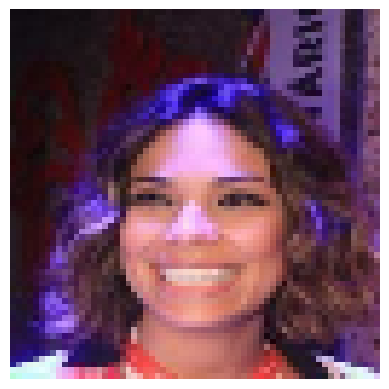

In [4]:
plt.axis("off")
plt.imshow(next(iter(dataset)).numpy()[0])
plt.show()

## Create the discriminator

It maps a 64×64 image to the probability that it is real: $D(x) \to 1$ for a real image, $D(x) \to 0$ for a fake one (slide "Discriminator"). Its stride-2 convolutions halve the size at each layer (64 → 32 → 16 → 8 → 4), with more and more channels.

In [5]:
discriminator = keras.Sequential(
  [
    keras.Input(shape=(64, 64, 3)),
    keras.layers.Conv2D(64, kernel_size=4, strides=2, padding="same"),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Conv2D(128, kernel_size=4, strides=2, padding="same"),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Conv2D(256, kernel_size=4, strides=2, padding="same"),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Conv2D(512, kernel_size=4, strides=2, padding="same"),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Flatten(),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation="sigmoid"),
  ],
  name="discriminator",
)
discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 512)      │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,768,321 (10.56 MB)

 Trainable params: 2,766,529 (10.55 MB)

 Non-trainable params: 1,792 (7.00 KB)

## Create the generator

It creates a 64×64 image from a noise vector $z$ (of size 128 here). It mirrors the discriminator: its stride-2 `Conv2DTranspose` layers double the size at each layer (4 → 8 → 16 → 32 → 64).

In [6]:
latent_dim = 128
generator = keras.Sequential(
  [
    keras.Input(shape=(latent_dim,)),
    keras.layers.Dense(4 * 4 * 1024),
    keras.layers.Reshape((4, 4, 1024)),
    keras.layers.Conv2DTranspose(512, kernel_size=4, strides=2, padding="same"),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Conv2DTranspose(256, kernel_size=4, strides=2, padding="same"),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same"),
    keras.layers.BatchNormalization(),
    keras.layers.LeakyReLU(negative_slope=0.2),
    keras.layers.Conv2DTranspose(
      3, kernel_size=4, strides=2, padding="same", activation="sigmoid"
    ),
  ],
  name="generator",
)
generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16384)          │     2,113,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 1024)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 512)      │     8,389,120 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 256)    │     2,097,408 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 3)      │         6,147 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,134,211 (50.10 MB)

 Trainable params: 13,132,419 (50.10 MB)

 Non-trainable params: 1,792 (7.00 KB)

## Override `train_step`

Each training step follows steps 3 and 4 of the slide "Learning Algorithm":

1. **Discriminator**: a batch of fake images (generated from noise) labeled 0, and of real ones labeled 1. The binary cross-entropy is then $-\log D(x) - \log(1 - D(G(z)))$: minimizing it maximizes the quantity of step 3.
2. **Generator**: new fake images, labeled 1 ("real"). The loss is $-\log D(G(z))$: the non-saturating loss of the slide "Generator", which gives a strong gradient early on, when $D$ easily rejects the fakes. Only the generator's weights are updated.

The discriminator's labels are noisy (real ones in $[0.95, 1]$, fake ones in $[0, 0.05]$): it becomes confident more slowly, and a discriminator that is too strong leaves no gradient for the generator.

Both networks are called with `training=True`: in an overridden `train_step`, Keras doesn't do it, and `BatchNormalization` and `Dropout` would run in inference mode.

In [7]:
class GAN(keras.Model):
  def __init__(self, discriminator, generator, latent_dim):
    super().__init__()
    self.discriminator = discriminator
    self.generator = generator
    self.latent_dim = latent_dim

  def compile(self, d_optimizer, g_optimizer, loss_fn):
    super().compile()
    self.d_optimizer = d_optimizer
    self.g_optimizer = g_optimizer
    self.loss_fn = loss_fn
    self.d_loss_metric = keras.metrics.Mean(name="d_loss")
    self.g_loss_metric = keras.metrics.Mean(name="g_loss")

  @property
  def metrics(self):
    return [self.d_loss_metric, self.g_loss_metric]

  def train_step(self, real_images):
    batch_size = tf.shape(real_images)[0]

    # Step 3: train the discriminator on fake and real images
    random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
    generated_images = self.generator(random_latent_vectors, training=True)
    # Noisy labels: real ones in [0.95, 1], fake ones in [0, 0.05]
    fake_labels = 0.05 * tf.random.uniform((batch_size, 1))
    real_labels = 0.95 + 0.05 * tf.random.uniform((batch_size, 1))
    # Real and fake images go through separately: mixed here and alone at step 4, they
    # would have different BatchNormalization statistics, which the generator would
    # use to fool D without producing faces
    with tf.GradientTape() as tape:
      fake_predictions = self.discriminator(generated_images, training=True)
      real_predictions = self.discriminator(real_images, training=True)
      d_loss = (
        self.loss_fn(fake_labels, fake_predictions)
        + self.loss_fn(real_labels, real_predictions)
      ) / 2
    grads = tape.gradient(d_loss, self.discriminator.trainable_weights)
    self.d_optimizer.apply_gradients(zip(grads, self.discriminator.trainable_weights))

    # Step 4: train the generator to make D predict 1 ("real"),
    # non-saturating loss -log D(G(z)); only the generator's weights change
    random_latent_vectors = tf.random.normal(shape=(batch_size, self.latent_dim))
    misleading_labels = tf.ones((batch_size, 1))
    with tf.GradientTape() as tape:
      generated_images = self.generator(random_latent_vectors, training=True)
      predictions = self.discriminator(generated_images, training=True)
      g_loss = self.loss_fn(misleading_labels, predictions)
    grads = tape.gradient(g_loss, self.generator.trainable_weights)
    self.g_optimizer.apply_gradients(zip(grads, self.generator.trainable_weights))

    self.d_loss_metric.update_state(d_loss)
    self.g_loss_metric.update_state(g_loss)
    return {
      "d_loss": self.d_loss_metric.result(),
      "g_loss": self.g_loss_metric.result(),
    }

## Create a callback that shows generated images during training

At the end of each epoch, it shows the images generated from the same 16 codes $z$: faces take shape from one epoch to the next.

In [8]:
def show_images(images, title, ncols=8):
  images = keras.ops.convert_to_numpy(images)
  nrows = len(images) // ncols
  fig, axes = plt.subplots(
    nrows, ncols, figsize=(1.5 * ncols, 1.5 * nrows), squeeze=False
  )
  for ax, image in zip(axes.flat, images):
    ax.imshow(image)
    ax.axis("off")
  fig.suptitle(title)
  plt.show()


class ImageGenerator(keras.callbacks.Callback):
  def __init__(self, num_img=16, latent_dim=128):
    super().__init__()
    # The same codes at every epoch
    rng = np.random.default_rng(0)
    self.random_latent_vectors = rng.normal(size=(num_img, latent_dim)).astype(
      "float32"
    )

  def on_epoch_end(self, epoch, logs=None):
    generated_images = self.model.generator(self.random_latent_vectors)
    show_images(generated_images, title=f"Epoch {epoch + 1}")

## Train the end-to-end model

To fit in a session (about 2 minutes on a GPU), 5 epochs of 10,000 images each, that is 50,000 of the dataset's 202,599 images; a real training runs dozens of epochs over the whole dataset.

The losses don't have to go down: each network improves against the other. A `d_loss` that goes to 0 means that the discriminator dominates, and that the generator no longer learns (slide "An Unstable Training"). In our run, `d_loss` stays around 0.2 and `g_loss` between 4 and 5: the discriminator dominates, but the generator improves all the same, as the images show. After 5 epochs, the faces are still blurry, with a checkerboard pattern and color casts.

Epoch 1/5
311/312 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - d_loss: 0.2074 - g_loss: 5.1868

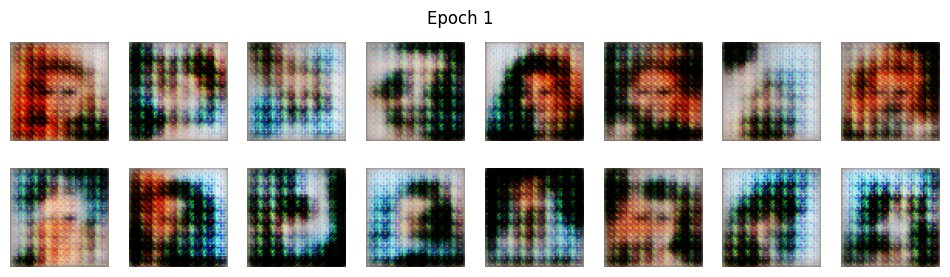

312/312 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - d_loss: 0.2034 - g_loss: 4.9701
Epoch 2/5
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - d_loss: 0.2379 - g_loss: 4.3997

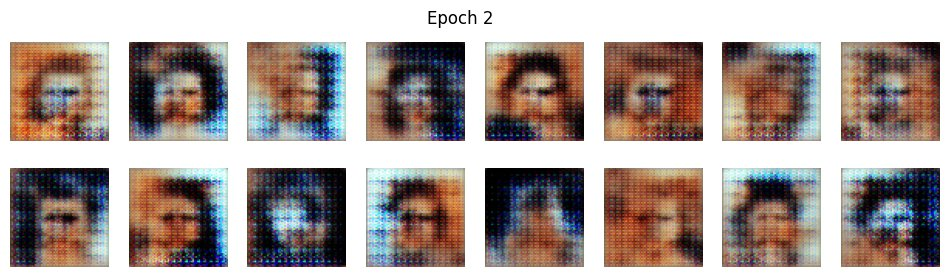

312/312 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - d_loss: 0.2427 - g_loss: 4.3995
Epoch 3/5
311/312 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - d_loss: 0.2332 - g_loss: 4.4029

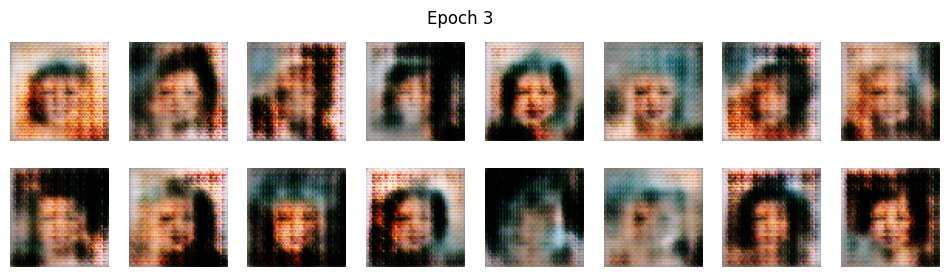

312/312 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - d_loss: 0.2321 - g_loss: 4.4043
Epoch 4/5
312/312 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - d_loss: 0.2231 - g_loss: 4.5315

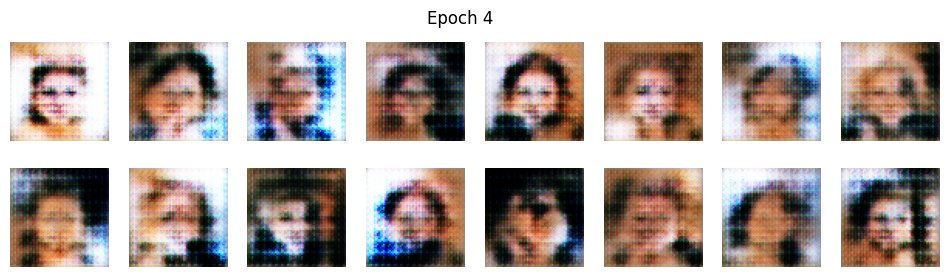

312/312 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - d_loss: 0.2275 - g_loss: 4.3620
Epoch 5/5
311/312 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - d_loss: 0.2279 - g_loss: 4.1334

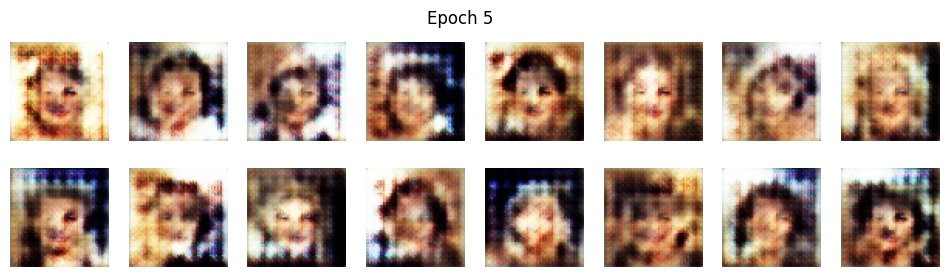

312/312 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - d_loss: 0.2286 - g_loss: 4.2738


In [9]:
epochs = 5
images_per_epoch = 10_000

gan = GAN(discriminator=discriminator, generator=generator, latent_dim=latent_dim)
gan.compile(
  d_optimizer=keras.optimizers.Adam(learning_rate=0.0001),
  g_optimizer=keras.optimizers.Adam(learning_rate=0.0001),
  loss_fn=keras.losses.BinaryCrossentropy(),
)

gan.fit(
  dataset.repeat(),
  epochs=epochs,
  steps_per_epoch=images_per_epoch // 32,
  callbacks=[ImageGenerator(num_img=16, latent_dim=latent_dim)],
)

## Interpolation in the latent space

Between two codes $z_1$ and $z_2$, the points $(1 - t)\,z_1 + t\,z_2$, for $t$ from 0 to 1, give faces that change continuously from one to the other: the generator has learned a continuous latent space, where close codes give close images.

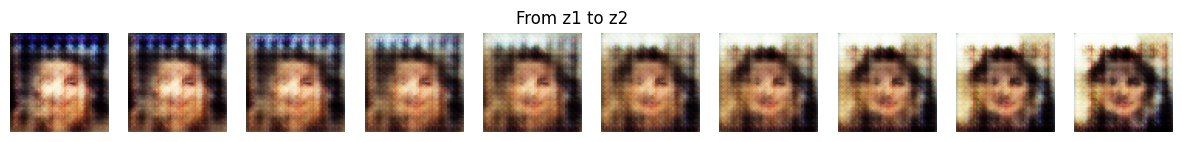

In [10]:
z1, z2 = np.random.default_rng(1).normal(size=(2, latent_dim)).astype("float32")
t = np.linspace(0, 1, 10)[:, None]
show_images(generator((1 - t) * z1 + t * z2), title="From z1 to z2", ncols=10)